# Experiment 2: local misspecification and robust weighting

The design fixes $a=2$, $c=1$, and $\beta=1$. The two single-source estimators then have the same exact-specification asymptotic variance, $V_{\mathrm{IV}}=V_{\mathrm{SV}}=1$. For each $n=200,400,\ldots,2000$, we simulate $n^{-1/2}$-local moment violations with $\kappa\in\{0,0.5,1\}$. At $\kappa=1$, the three regimes let only IV, only SV, or both moment channels deviate. Thus SV-only is the stronger single-source benchmark when IV may deviate, while IV-only is stronger when SV may deviate. Each uncertainty set $C$ is prespecified before estimation; the weight does not use the true $\tau$.

The simulation evaluates every vertex of each symmetric box. **Worst-case scaled MSE** is the maximum of $n\,\widehat{\mathrm{MSE}}$ across its vertices. **Minimum coverage** is the minimum empirical coverage across vertices. The IV-only and SV-only methods provide single-channel benchmarks; equal GMM and local-risk GMM use sample projections; local-risk GMM also estimates the projected-score covariance from the sample. The local-risk method minimizes estimated worst-case bias squared plus variance over normalized positive-semidefinite weights satisfying $\widehat J^\top M\widehat J\ge 10^{-4}$. Robust confidence intervals use the same prespecified box and the sample-based bias bound from Remark 9.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / "results" / "local_misspec" / "local_misspec_worst_case.csv").exists():
    root = root / "unification-control-modelling"
result_dir = root / "results" / "local_misspec"
corners = pd.read_csv(result_dir / "local_misspec_corners.csv")
worst = pd.read_csv(result_dir / "local_misspec_worst_case.csv")
assert len(corners) == 680 and len(worst) == 280
assert set(corners["replications"]) == {1000}
assert set(worst["kappa"]) == {0.0, 0.5, 1.0}
assert set(worst["n"]) == set(range(200, 2001, 200))
assert np.allclose(corners["scaled_mse"], corners["scaled_squared_bias"] + corners["scaled_variance"], atol=1e-8)

regimes = ("iv", "sv", "both")
regime_labels = {"iv": "IV channel may deviate", "sv": "SV channel may deviate", "both": "Both channels may deviate"}
methods = ("iv", "sv", "equal", "local_risk")
method_labels = {"iv": "IV only", "sv": "SV only", "equal": "Equal GMM", "local_risk": "Local-risk GMM"}
colors = {"iv": "#4477AA", "sv": "#EE6677", "equal": "#228833", "local_risk": "#332288"}
markers = {"iv": "o", "sv": "s", "equal": "^", "local_risk": "D"}
n_values = sorted(worst["n"].unique())
print(f"Loaded {len(corners)} vertex summaries and {len(worst)} worst-case summaries.")


Loaded 680 vertex summaries and 280 worst-case summaries.


## Main Figure 1: worst-case scaled MSE as $n$ increases

The top panel is the common **correct-specification baseline** $\kappa=0$, where all regimes have $C=\{0\}$. The lower three panels compare the four estimators at $\kappa=1$. Each black dashed line is the corresponding **population minimum worst-case local risk**. Scaling MSE by $n$ makes the local bias--variance tradeoff visible as sample size changes.

The one-sided regimes reverse which single-source estimator is preferable: SV-only is protected when IV may deviate, and IV-only is protected when SV may deviate. The population local-risk optimum strictly improves on both single-source estimators and equal GMM in all three regimes by combining the remaining precision with reduced sensitivity to the unreliable moment.


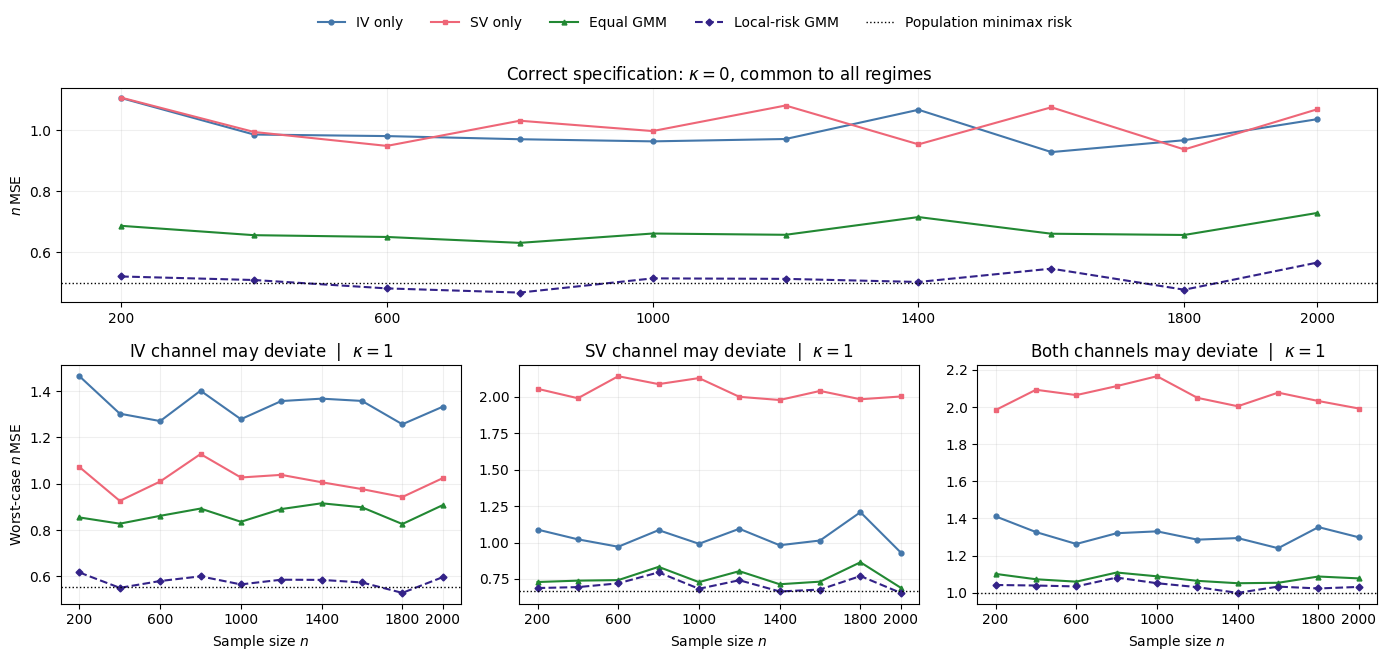

In [2]:
fig = plt.figure(figsize=(14, 6.5))
grid = fig.add_gridspec(2, 3, height_ratios=(0.9, 1))
baseline_ax = fig.add_subplot(grid[0, :])
axes = np.array([fig.add_subplot(grid[1, col]) for col in range(3)])

def draw_risk_panel(ax, panel, title):
    for method in methods:
        values = panel[panel["method"] == method].sort_values("n")
        ax.plot(values["n"], values["worst_scaled_mse"],
                color=colors[method], marker=markers[method], markersize=3.5,
                linestyle="--" if method == "local_risk" else "-",
                linewidth=1.5, label=method_labels[method])
    bound = panel.loc[panel["method"] == "local_risk", "theoretical_worst_risk"].iloc[0]
    ax.axhline(bound, color="black", linestyle=":", linewidth=1,
               label="Population minimax risk")
    ax.set_title(title)
    ax.set_xticks(n_values[::2] + [n_values[-1]])
    ax.grid(alpha=0.2)

baseline = worst[(worst["kappa"] == 0) & (worst["regime"] == "none")]
draw_risk_panel(baseline_ax, baseline, r"Correct specification: $\kappa=0$, common to all regimes")
baseline_ax.set_ylabel(r"$n\,\mathrm{MSE}$")
for col, regime in enumerate(regimes):
    ax = axes[col]
    panel = worst[(worst["kappa"] == 1.0) & (worst["regime"] == regime)]
    draw_risk_panel(ax, panel, rf"{regime_labels[regime]}  |  $\kappa=1$")
    if col == 0:
        ax.set_ylabel(r"Worst-case $n\,\mathrm{MSE}$")
    ax.set_xlabel("Sample size $n$")
handles, labels = baseline_ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(result_dir / "local_misspec_risk.pdf", bbox_inches="tight")
fig.savefig(result_dir / "local_misspec_risk.png", dpi=300, bbox_inches="tight")
plt.show()


## Main Figure 2: interval coverage and length as $n$ increases

Fix $\kappa=1$ and compare the two combined point estimators. Each method has a conventional Wald interval and a misspecification-robust interval. The upper panels plot the *minimum* 95% interval coverage over all vertices in $C$; the lower panels plot interval length averaged over the vertices. The horizontal line marks 95% coverage. A robust interval may be longer, and the MSE-optimal weight need not produce the shortest robust interval.


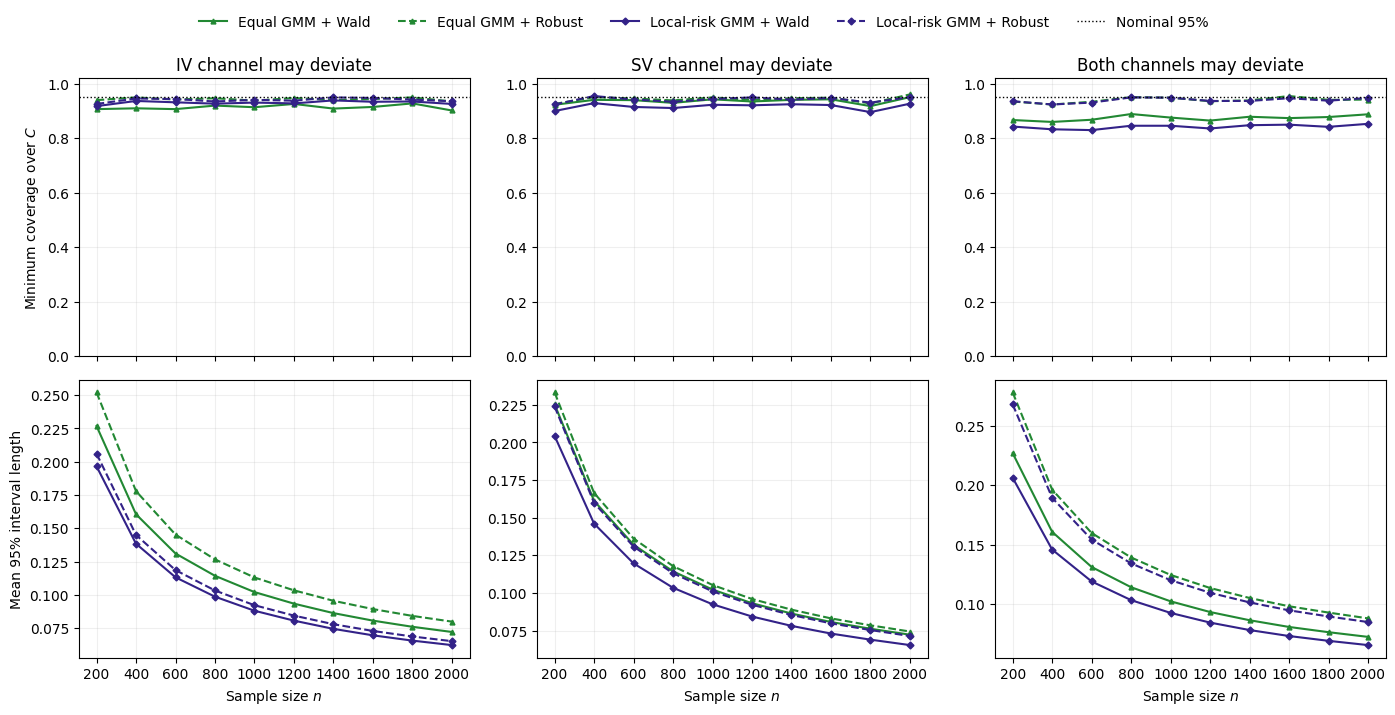

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
intervals = (("wald", "Wald", "-"), ("robust", "Robust", "--"))
for col, regime in enumerate(regimes):
    panel = worst[(worst["kappa"] == 1.0) & (worst["regime"] == regime)]
    for method in ("equal", "local_risk"):
        values = panel[panel["method"] == method].sort_values("n")
        for interval, label, linestyle in intervals:
            axes[0, col].plot(values["n"], values[f"min_{interval}_coverage"],
                              color=colors[method], linestyle=linestyle, marker=markers[method],
                              markersize=3.5, linewidth=1.5,
                              label=f"{method_labels[method]} + {label}")
            axes[1, col].plot(values["n"], values[f"mean_{interval}_length"],
                              color=colors[method], linestyle=linestyle, marker=markers[method],
                              markersize=3.5, linewidth=1.5)
    axes[0, col].axhline(0.95, color="black", linestyle=":", linewidth=1, label="Nominal 95%")
    axes[0, col].set_title(regime_labels[regime])
    axes[0, col].set_ylim(0, 1.02)
    axes[1, col].set_xlabel("Sample size $n$")
    for row in range(2):
        axes[row, col].set_xticks(n_values)
        axes[row, col].grid(alpha=0.2)
axes[0, 0].set_ylabel("Minimum coverage over $C$")
axes[1, 0].set_ylabel("Mean 95% interval length")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.025))
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(result_dir / "local_misspec_inference.pdf", bbox_inches="tight")
fig.savefig(result_dir / "local_misspec_inference.png", dpi=300, bbox_inches="tight")
plt.show()


## Concise results check

The following checks summarize the $\kappa=1$ design at $n=2000$. The local-risk comparison concerns maximum risk over each prespecified set. Full corner-level decompositions, coverage, and interval lengths remain in the CSV summaries.


In [4]:
for regime in regimes:
    panel = worst[(worst["regime"] == regime) & (worst["kappa"] == 1.0) & (worst["n"] == 2000)]
    values = panel.set_index("method")
    local = values.loc["local_risk"]
    equal = values.loc["equal"]
    best_single = min(values.loc["iv", "worst_scaled_mse"], values.loc["sv", "worst_scaled_mse"])
    improvement = 100 * (1 - local["worst_scaled_mse"] / equal["worst_scaled_mse"])
    print(f"{regime_labels[regime]}: local-risk worst-case n*MSE={local['worst_scaled_mse']:.3f}; "
          f"equal={equal['worst_scaled_mse']:.3f}; best single={best_single:.3f}; "
          f"change vs equal={improvement:+.1f}%")
    print(f"  population minimax risk={local['theoretical_worst_risk']:.3f}; "
          f"mean IV information share={local['mean_iv_share']:.3f}; "
          f"minimum robust coverage={local['min_robust_coverage']:.3f}")

valid = worst[(worst["regime"] == "none") & (worst["kappa"] == 0)]
reference = valid.pivot(index="n", columns="method", values="worst_scaled_mse")
print("At kappa=0, largest absolute empirical risk difference between local-risk and equal:",
      round((reference["local_risk"] - reference["equal"]).abs().max(), 6))


IV channel may deviate: local-risk worst-case n*MSE=0.596; equal=0.907; best single=1.024; change vs equal=+34.3%
  population minimax risk=0.556; mean IV information share=0.445; minimum robust coverage=0.936
SV channel may deviate: local-risk worst-case n*MSE=0.654; equal=0.689; best single=0.931; change vs equal=+5.1%
  population minimax risk=0.667; mean IV information share=0.667; minimum robust coverage=0.951
Both channels may deviate: local-risk worst-case n*MSE=1.032; equal=1.077; best single=1.298; change vs equal=+4.3%
  population minimax risk=1.000; mean IV information share=0.667; minimum robust coverage=0.948
At kappa=0, largest absolute empirical risk difference between local-risk and equal: 0.212994
